<a href="https://www.kaggle.com/code/makrrc/8-78784-v5-s60-predicting-student-test-scores?scriptVersionId=292658695" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

[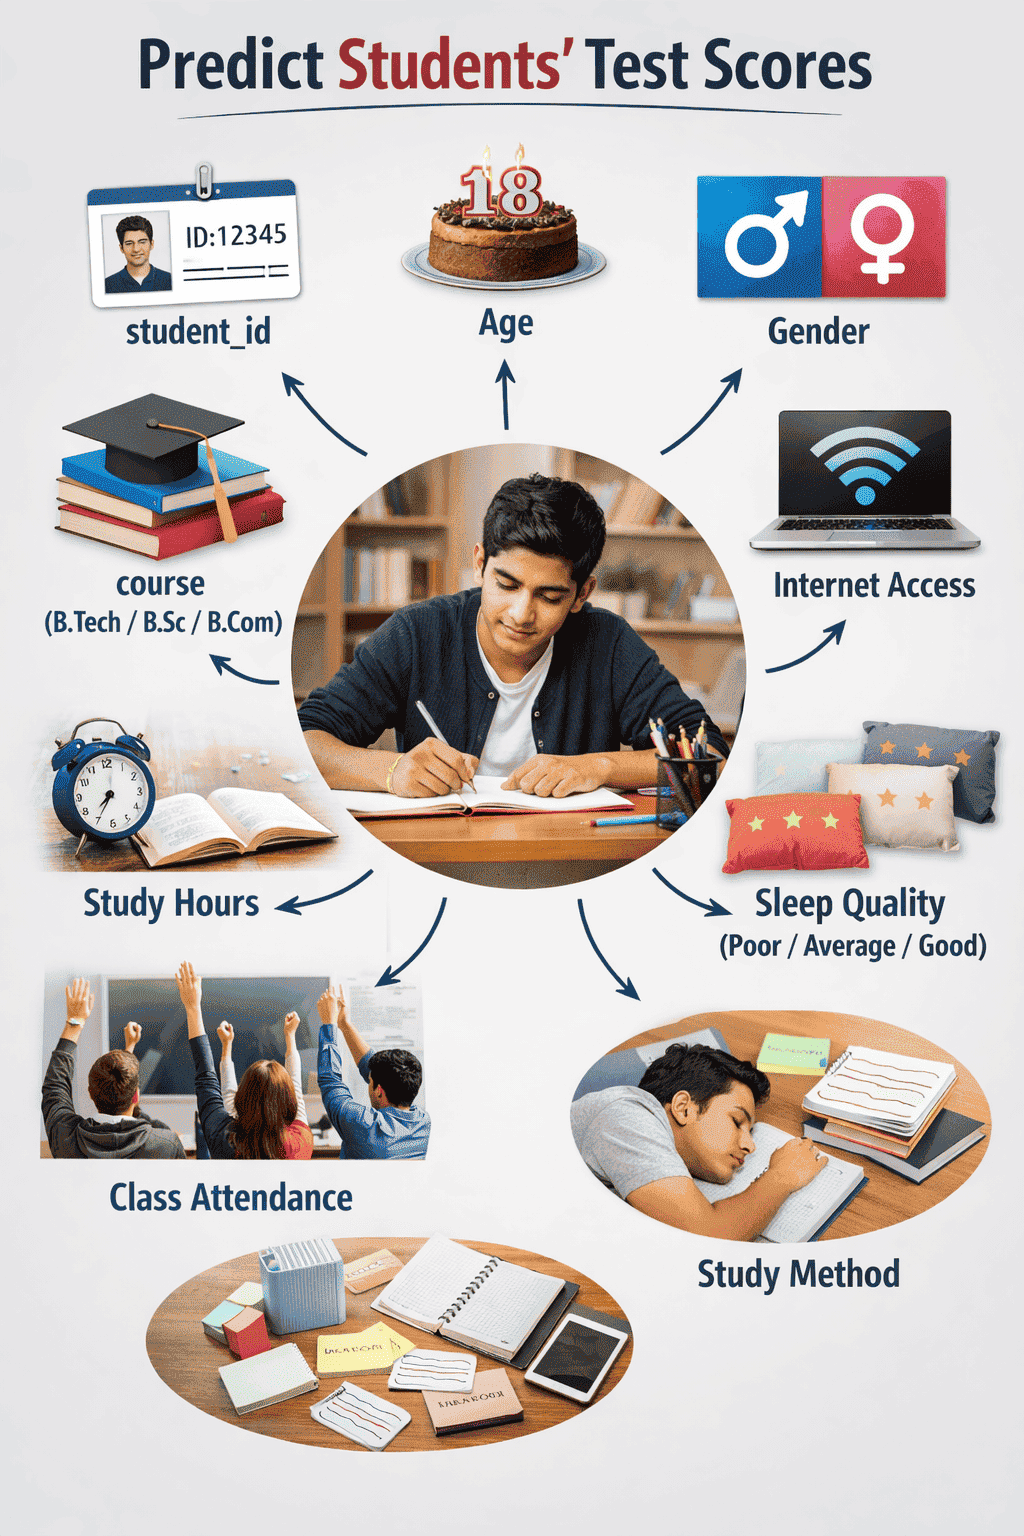!](http://)

<h2>Your Goal:</h2> 
Predict students' test scores.


student_id
Unique identifier assigned to each student

age
Age of the student

gender
Gender identity

course
Academic program (B.Tech, B.Sc, B.Com, etc.)

study_hours
Daily study duration

class_attendance
Attendance percentage

internet_access
Availability of internet

sleep_hours
Daily sleep duration

sleep_quality
Quality of sleep (Poor/Average/Good)

study_method
Primary study technique

Evaluation
Submissions are evaluated using the Root Mean Squared Error between the predicted and the observed target.

<h2>Original data:</h2>


About Dataset
This dataset provides an extensive and realistic representation of various factors that contribute to student exam performance. It contains 20,000 records, each describing a student’s academic behavior, study habits, lifestyle routines, and exam conditions. These variables collectively help understand how different aspects of a student’s daily life and learning environment influence their exam outcomes.

The dataset includes details such as daily study hours, class attendance percentage, sleep duration and quality, internet availability, study method, institutional facility rating, and exam difficulty level. These factors reflect a broad spectrum of influences commonly observed in educational settings. The exam score (0–100) is derived using a weighted formula that mimics real-life academic performance patterns.

For example:

Higher study hours and consistent attendance often correlate with stronger performance.
Better sleep quality and balanced rest contribute positively.
Coaching and mixed study methods typically help students achieve higher marks.
Limited internet access or poor institutional facilities may create a disadvantage.
Harder exam papers reduce achievable scores, while easier ones increase performance.

The dataset is fully synthetic yet designed to mirror logical and realistic student behavior. It contains no personally identifiable information and is suitable for educational research, statistical exploration, behavior analysis, institution-level studies, and general data-driven insights.

Whether used for visualizing score distributions, comparing study habits, evaluating lifestyle effects, or simply exploring student performance patterns, this dataset provides a well-structured and diverse foundation for understanding exam outcomes.

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
from xgboost import XGBRegressor

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
train = pd.read_csv("/kaggle/input/playground-series-s6e1/train.csv")
test = pd.read_csv("/kaggle/input/playground-series-s6e1/test.csv")

In [ ]:
origin = pd.read_csv("/kaggle/input/exam-score-prediction-dataset/Exam_Score_Prediction.csv")

In [ ]:
origin.info()

In [ ]:
le = LabelEncoder()
def CodificarLabelEncode(Dataset, columns, LabelEncoder):
    LabelEncoder.fit(Dataset[columns])
    Dataset['le_'+columns] = le.transform(Dataset[columns])
    return Dataset

In [ ]:
oe = OrdinalEncoder()

def CodificarOrdinalEncoder(dataset, column, encoder):
    """
    Codifica uma coluna categórica usando OrdinalEncoder e
    adiciona uma nova coluna codificada ao DataFrame.
    """
    # O erro estava aqui: precisamos passar [[column]] para garantir 2D
    encoder.fit(dataset[[column]])  
    dataset['oe_' + column] = encoder.transform(dataset[[column]])
    return dataset

In [ ]:
def get_dummies1(dataset, column):
    result = ''
    for elemento in column:
        print(elemento)
        temp = pd.get_dummies(dataset[elemento])
        dataset = pd.concat([dataset, temp], axis=1)
    return dataset   

In [ ]:
def get_bool(dataset, column):
    temp = dataset[column].replace({True:1,False:0})
    temp = temp
    return temp

In [ ]:
def get_bool1(dataset, column):
    temp = dataset[column].replace({'yes':1,'no':0})
    temp = temp
    return temp

In [ ]:
train.columns

In [ ]:
test.head(n=2)

In [ ]:
origin.describe()

In [ ]:
train.min()

In [ ]:
train.max()

In [ ]:
origin.max()

In [ ]:
train['internet_access'] = get_bool1(train, ['internet_access'])
train

In [ ]:
test['internet_access'] = get_bool1(test, ['internet_access'])
test

In [ ]:
train = get_dummies1(train, ['gender'])
train

In [ ]:
test = get_dummies1(test, ['gender'])
test

In [ ]:
train['female'] = get_bool(train, ['female'])
train

In [ ]:
test['female'] = get_bool(test, ['female'])
test

In [ ]:
train['male'] = get_bool(train, ['male'])
train

In [ ]:
test['male'] = get_bool(test, ['male'])
test

In [ ]:
train['other'] = get_bool(train, ['other'])
train

In [ ]:
test['other'] = get_bool(test, ['other'])
test

In [ ]:
train.course.unique()

In [ ]:
train = CodificarOrdinalEncoder(train, 'course', oe)
train

In [ ]:
test = CodificarOrdinalEncoder(test, 'course', oe)
test

In [ ]:
train = CodificarLabelEncode(train,'sleep_quality',le)
train

In [ ]:
test = CodificarLabelEncode(test,'sleep_quality',le)
test

In [ ]:
train = CodificarLabelEncode(train,'study_method',le)
train

In [ ]:
test = CodificarLabelEncode(test,'study_method',le)
test

In [ ]:
train = CodificarOrdinalEncoder(train, 'facility_rating', oe)
train

In [ ]:
test = CodificarOrdinalEncoder(test, 'facility_rating', oe)
test

In [ ]:
train = CodificarOrdinalEncoder(train, 'exam_difficulty', oe)
train

In [ ]:
test = CodificarOrdinalEncoder(test, 'exam_difficulty', oe)
test

In [ ]:
train = CodificarLabelEncode(train,'study_method',le)
train

In [ ]:
test = CodificarLabelEncode(test,'study_method',le)
test

In [ ]:
train.columns

In [ ]:
train[['age', 'study_hours', 'class_attendance','internet_access', 'sleep_hours', 'oe_course', 'le_sleep_quality', 'le_study_method','oe_facility_rating', 'oe_exam_difficulty', 'exam_score']]

In [ ]:
test[['id','age', 'study_hours', 'class_attendance','internet_access', 'sleep_hours', 'oe_course', 'le_sleep_quality', 'le_study_method','oe_facility_rating', 'oe_exam_difficulty']]

In [ ]:
train.info()

In [ ]:
train.hist()

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
feature = train.select_dtypes(exclude='object').drop(columns='exam_score').columns

In [ ]:
test[ feature ]

In [ ]:
# performing preprocessing part
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

train_projected = sc.fit_transform(train.loc[:, feature])
test_projected = sc.transform(test[feature])

In [ ]:
# Applying PCA function on training
# and testing set of X component
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

projected_train = pca.fit_transform(train_projected)
projected_test = pca.transform(test_projected)

explained_variance = pca.explained_variance_ratio_

In [ ]:
explained_variance

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)

In [ ]:
# 3. Fit the model to the data and predict the cluster labels
kmeans.fit(train[feature])
labels = kmeans.predict(train[feature])

In [ ]:
# Alternatively, use fit_predict in one step:
labels = kmeans.fit_predict(test[feature])

In [ ]:
# 4. Get the cluster centers
centroids = kmeans.cluster_centers_

In [ ]:
# plt.scatter(projected_test[:,0], projected_test[:,1], projected_test[:,2])

In [ ]:
# # 5. Visualize the results (optional)
# plt.scatter(projected_test[:, 0], projected_test[:, 1], c=labels, s=50, cmap='viridis')
# plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='*')
# plt.title('K-Means Clustering')
# plt.xlabel('Feature 1')
# plt.ylabel('Feature 2')
# plt.show()

In [ ]:
import seaborn as sns

In [ ]:
cols = feature.values.tolist() + ['exam_score']

In [ ]:
sns.heatmap(train[cols].corr())

In [ ]:
origin.dtypes

In [ ]:
sns.heatmap( origin.loc[:,origin.dtypes != 'object'].corr() )

In [ ]:
origin['study_hours_class_attendance']  = origin['class_attendance'] * origin['study_hours']

In [ ]:
origin['tax_sleep_hours_age']  = origin['sleep_hours'] / origin['age']

In [ ]:
origin['study_sleep_hours']  = origin['study_hours'] * origin['sleep_hours']

In [ ]:
train['study_hours_class_attendance']  = train['class_attendance'] * train['study_hours']

In [ ]:
train['tax_sleep_hours_age']  = train['sleep_hours'] / train['age']

In [ ]:
train['study_sleep_hours']  = train['study_hours'] * train['sleep_hours']

In [ ]:
test['study_hours_class_attendance']  = test['class_attendance'] * test['study_hours']

In [ ]:
test['tax_sleep_hours_age']  = test['sleep_hours'] / test['age']

In [ ]:
test['study_sleep_hours']  = test['study_hours'] * test['sleep_hours']

In [ ]:
sns.heatmap(origin.select_dtypes(exclude='object').corr())

In [ ]:
# X = train[['age', 'study_hours', 'class_attendance','internet_access', 'sleep_hours', 'oe_course', 'le_sleep_quality', 'le_study_method','oe_facility_rating', 'oe_exam_difficulty']]

In [ ]:
X = train[['age', 'study_hours', 'class_attendance','internet_access', 'sleep_hours', 'oe_course', 'le_sleep_quality', 'le_study_method','oe_facility_rating', 'oe_exam_difficulty', 'study_hours_class_attendance', 'tax_sleep_hours_age']]

In [ ]:
y = train['exam_score']

In [ ]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model_XGBRegressor = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

In [ ]:
model_XGBRegressor.fit(X_train, y_train)

In [ ]:
# Access using the scikit-learn API attribute (default is 'gain')
importance_gain = model_XGBRegressor.feature_importances_

# Access using the booster object to specify type
booster = model_XGBRegressor.get_booster()
importance_weight = booster.get_score(importance_type='weight')

In [ ]:
importance_weight

In [ ]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))  
plot_importance(
    model_XGBRegressor,
    ax=ax,
    importance_type="gain", # or "weight", "cover"
    max_num_features=40,
    height=0.5,
)
ax.set_title("XGB Feature Importance (last fold)")
fig.tight_layout()
plt.show()

In [ ]:
model_XGBRegressor

In [ ]:
importances = model_XGBRegressor.feature_importances_
importances

In [ ]:
feature_importance = pd.Series(importances, index=X.columns).sort_values(ascending=False)

In [ ]:
features = []
for fi, value in feature_importance.items():
    if value>0.03:
        print(fi,' ',value)
        features.append(fi)


In [ ]:
model_XGBRegressor.fit(X_train[features], y_train)

In [ ]:
y_pred = model_XGBRegressor.predict(X_test[features])

In [ ]:
from sklearn.metrics import root_mean_squared_error

In [ ]:
valid = root_mean_squared_error(y_test, y_pred)
valid

1º 8.779836446839589 <br>
2º 8.774681088307323

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
regressor = RandomForestRegressor(n_estimators=10, random_state=0, oob_score=True)

In [ ]:
regressor.fit(X_train, y_train)

In [ ]:
# Get and display feature importances
importances = regressor.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print(feature_importance_df)

In [ ]:
features

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [ ]:
# tree_to_plot = regressor.estimators_[0]

In [ ]:
# plt.figure(figsize=(20, 10))

In [ ]:
X_train.columns.shape

In [ ]:
pd.Series(regressor.feature_importances_, index=X_train.columns)\
  .sort_values(ascending=False)\
  .head(20)\
  .plot(kind='barh')

In [ ]:
importance_rando_forest = pd.Series(regressor.feature_importances_, index=X.columns)

In [ ]:
features = []
features

In [ ]:
features = []
for fi, value in importance_rando_forest.items():
    if value>0.03:
        print(fi,' ',value)
        features.append(fi)


In [ ]:
regressor.fit(X_train[features], y_train)

In [ ]:
y_pred = regressor.predict(X_test[features])

In [ ]:
valid = root_mean_squared_error(y_test, y_pred)
valid

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor

In [ ]:
ExtraTreesRegressor = ExtraTreesRegressor(n_estimators=100, random_state=0).fit(X_train, y_train)

In [ ]:
pd.Series(ExtraTreesRegressor.feature_importances_, index=X.columns)\
  .sort_values(ascending=False)\
  .head(20)\
  .plot(kind='barh')

In [ ]:
ExtraTreesRegressor_fi = pd.Series(ExtraTreesRegressor.feature_importances_, index=X.columns)
ExtraTreesRegressor_fi

In [ ]:
features = []
for fi, value in ExtraTreesRegressor_fi.items():
    if value>0.03:
        print(fi,' ',value)
        features.append(fi)

In [ ]:
regressor.fit(X_train[features], y_train)

In [ ]:
y_pred = regressor.predict(X_test[features])

In [ ]:
valid = root_mean_squared_error(y_test, y_pred)
valid

In [ ]:
from sklearn.linear_model import ElasticNet

In [ ]:
ElasticNet = ElasticNet(random_state=0)

In [ ]:
en = ElasticNet.fit(X_train, y_train)

In [ ]:
en.predict(X_test)

In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
feature_importance = pd.Series(index = X_train.columns, data = np.abs(ElasticNet.coef_))

n_selected_features = (feature_importance>0).sum()
print('{0:d} features, reduction of {1:2.2f}%'.format(
    n_selected_features,(1-n_selected_features/len(feature_importance))*100))

feature_importance.sort_values().tail(30).plot(kind = 'bar', figsize = (18,6))

In [ ]:
pd.Series(feature_importance, index=X.columns)\
  .sort_values(ascending=False)\
  .head(20)\
  .plot(kind='barh')

In [ ]:
type(feature_importance)

In [ ]:
features = []
for feature, value in feature_importance.items():
    if value > 0:
        features.append(feature)
        # print(feature, ' - ' ,value)

In [ ]:
en = ElasticNet.fit(X_train[features], y_train)

In [ ]:
y_pred = en.predict(X_test[features])

In [ ]:
valid = root_mean_squared_error(y_test, y_pred)
valid

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

In [ ]:
estimators = [
    ('xgbr', model_XGBRegressor),
    ('rf', regressor),
    ('etr', ExtraTreesRegressor),
    ('en', ElasticNet)
]

In [ ]:
reg = StackingRegressor(
    estimators=estimators,
    final_estimator=LinearRegression()
)

In [ ]:
reg.fit(X_train, y_train).score(X_test, y_test)

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
# pred = np.clip(y_pred, 0, 1)

In [ ]:
y_test = reg.predict(X_test)

In [ ]:
valid = root_mean_squared_error(y_test, y_pred)
valid

In [ ]:
def score_model(model, X, y):
    """Evaluate the trained model and returns a dictionary with eval metrics"""
    # make predictions
    y_pred = model.predict(X)
    # return metrics & predictions
    return {
        "mse": mean_squared_error(y, y_pred),
        "rmse": root_mean_squared_error(y, y_pred),
        "r2": r2_score(y, y_pred),
        "y_pred": y_pred,
    }

In [ ]:
score_model(reg, X, y)

In [ ]:
X_train.shape

In [ ]:
test.shape

In [ ]:
X_train.columns

In [ ]:
test[['age', 'study_hours', 'class_attendance', 'internet_access',
       'sleep_hours', 'oe_course', 'le_sleep_quality', 'le_study_method',
       'oe_facility_rating', 'oe_exam_difficulty']].columns

In [ ]:
submit = reg.predict(test[X_test.columns])

In [ ]:
submission_final = pd.DataFrame({

        "id": test['id'],

        "exam_score": submit

    })

In [ ]:
## Submit notebooks to the challenge. Final

submission_final.to_csv('submission.csv', index=False)


print(" Arquivo submission.csv pronto ")

In [ ]:
submission_final